# FraudRadar: a fraud model on real card payments (IEEE-CIS)

This notebook trains a LightGBM fraud model on the [IEEE-CIS Fraud Detection](https://www.kaggle.com/competitions/ieee-fraud-detection)
data: about 590,000 real, anonymised online card payments from Vesta, 3.5% of them fraud. It is the real-data
counterpart of the PaySim notebook. PaySim is a simulation, so its near-perfect score says little about real fraud;
this one shows what the same method gets on payments where nobody wrote the fraud rule.

**How to run it on Kaggle**
1. Join the competition once: open <https://www.kaggle.com/competitions/ieee-fraud-detection>, choose **Join Competition** and accept the rules.
2. Create a new notebook, then **File > Import Notebook** and upload this file.
3. In the right-hand panel choose **Add Input > Competition Datasets**, search for `IEEE-CIS Fraud Detection` and add it.
4. Leave the accelerator on **None** (CPU). Switch **Internet** on only if the first cell says a library is missing.
5. Run from the top. Do a first run with `QUICK = True` (a few minutes), then set it to `False` for the real one.
6. Results are in `/kaggle/working/out`. The last cell makes a zip and a download link.

**What is used.** Only `train_transaction.csv` and `train_identity.csv`, because they are the only files with
labels. The competition's own `test_*` files have no answers, so this notebook makes its own test part from the end of
the training file's timeline.

**The ideas this notebook is built around**
- **Split by time, not at random.** The model is tested on payments that come after the ones it learned from.
- **Features use only what was known before the payment.** The history features count earlier payments only.
- **At 3.5% fraud, accuracy is meaningless.** Average precision, ROC AUC and the share of fraud caught at a fixed
  false-alarm rate are reported.
- **Real fraud drifts.** The score is also shown for four successive slices of the test period.

In [1]:
# Install only what is missing. Kaggle ships pandas, numpy, scikit-learn and matplotlib, and usually LightGBM.
import importlib.util
import subprocess
import sys

missing = [pkg for pkg in ("lightgbm",) if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("installed just now:", missing or "nothing (everything was already there)")

installed just now: nothing (everything was already there)


In [2]:
import gc
import hashlib
import json
import os
import shutil
import time
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)

KAGGLE_INPUT = Path("/kaggle/input")
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ or KAGGLE_INPUT.exists()

# ---- settings you may want to change -----------------------------------------------------------------------
SEED = 7
QUICK = False            # True: a fast first run to check everything works. Set to False for the real run.
ABLATION = True         # also train without the history features to see what they add

TRAIN_END, VALID_END = 0.60, 0.80   # share of the timeline: train up to 60%, validate 60-80%, test the last 20%
FPR_TARGETS = (0.05, 0.01)          # false-alarm rates to report: 5% and 1% of honest payments
MIN_CATEGORY_COUNT = 50             # a text value seen fewer times than this in the training part is treated as missing
MAX_ROUNDS = 400 if QUICK else 5000
LEARNING_RATE = 0.1 if QUICK else 0.03
# -------------------------------------------------------------------------------------------------------------

WORK = Path("/kaggle/working") if IN_KAGGLE else Path("work")
OUT_DIR = WORK / "out"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Kaggle:", IN_KAGGLE, "| quick run:", QUICK, "| lightgbm", lgb.__version__, "| pandas", pd.__version__)

Kaggle: True | quick run: False | lightgbm 4.6.0 | pandas 2.3.3


## 1. Get the data

The cell looks for `train_transaction.csv` under the `IEEE_DIR` environment variable, then under `/kaggle/input`, then
under `work/data` and `training/data/ieee`. On Kaggle just attach the competition data with **Add Input**.

In [3]:
def find_data_dir():
    roots = []
    if os.environ.get("IEEE_DIR"):
        roots.append(Path(os.environ["IEEE_DIR"]))
    roots += [KAGGLE_INPUT, WORK / "data", Path("training/data/ieee")]
    for root in roots:
        if root.exists():
            hits = sorted(root.rglob("train_transaction.csv"))
            if hits:
                return hits[0].parent
    return None


DATA = find_data_dir()
if DATA is None:
    raise FileNotFoundError(
        "train_transaction.csv not found. On Kaggle: join the competition (kaggle.com/competitions/ieee-fraud-detection), "
        "then Add Input > Competition Datasets > IEEE-CIS Fraud Detection. Elsewhere: set IEEE_DIR to the folder with the CSVs.")
print("Using", DATA)

Using /kaggle/input/competitions/ieee-fraud-detection


## 2. Load and look

The transaction table has one row per payment; the identity table (device and browser information) exists for about a
quarter of them. They are joined on `TransactionID`. Float columns are stored as 32-bit to save memory.

In [4]:
def read(name):
    frame = pd.read_csv(DATA / name)
    for col in frame.select_dtypes("float64"):
        frame[col] = frame[col].astype("float32")
    return frame


t0 = time.time()
tx = read("train_transaction.csv")
ident = read("train_identity.csv")
df = tx.merge(ident, on="TransactionID", how="left")
df["has_identity"] = df["TransactionID"].isin(ident["TransactionID"]).astype("int8")
del tx, ident
gc.collect()

if not df["TransactionDT"].is_monotonic_increasing:  # events must be in time order; the history features rely on it
    df = df.sort_values("TransactionDT", kind="stable").reset_index(drop=True)

labels = df["isFraud"].to_numpy().astype(bool)
dt = df["TransactionDT"].to_numpy()
print(f"{len(df):,} payments, {df.shape[1]} columns, loaded in {time.time() - t0:.0f}s")
print(f"fraud: {labels.sum():,} = {labels.mean() * 100:.2f}%   timeline: {(dt.max() - dt.min()) / 86400:.0f} days")

590,540 payments, 435 columns, loaded in 24s
fraud: 20,663 = 3.50%   timeline: 182 days


## 3. Split by time

Train on the earliest 60% of the timeline, choose settings and thresholds on the next 20%, and keep the last 20% for
the final score. **Do not tune anything on the test part.**

In [5]:
t_train, t_valid = np.quantile(dt, [TRAIN_END, VALID_END])
is_train = dt <= t_train
is_valid = (dt > t_train) & (dt <= t_valid)
is_test = dt > t_valid

split = pd.DataFrame(
    {"days": [f"{(dt[m].min() - dt.min()) / 86400:.0f}-{(dt[m].max() - dt.min()) / 86400:.0f}" for m in (is_train, is_valid, is_test)],
     "payments": [int(m.sum()) for m in (is_train, is_valid, is_test)],
     "fraud": [int(labels[m].sum()) for m in (is_train, is_valid, is_test)]},
    index=["train", "validation", "test"])
split["fraud_rate_%"] = (split["fraud"] / split["payments"] * 100).round(2)
assert (split["fraud"] >= 50).all(), "Too few fraud cases in a split to measure anything reliably."
split

,days,payments,fraud,fraud_rate_%
train,0-100,354324,11988,3.38
validation,100-140,118108,4611,3.90
test,140-182,118108,4064,3.44


## 4. Features

**Group A: what the payment itself says.** Every column of the two tables except the identifier, the label and the raw
timestamp (`TransactionDT` is seconds since an unknown start, so using it directly would only teach the model "later
than anything I saw"). Instead the hour of the day and the day of the week are derived from it. Text columns become
categories whose levels are learned from the **training part only**; a level seen fewer than `MIN_CATEGORY_COUNT`
times there, or never, is treated as missing.

**Group B: history of a proxy account.** The data has no account number. Payments that share the card attributes
`card1, card2, card3, card5` and the billing zone `addr1` are treated as one account. This is a guess made by many
competitors, not a fact, so the group is called *proxy*. For each payment the features count only **earlier** payments
of the same proxy account: how many there were, how long ago the last one was, and how the amount compares with their
average. The same is done for the purchaser's email domain.

The `V1`-`V339` columns are Vesta's own engineered features and are anonymised; they cannot be explained, only used.

In [6]:
LABEL, DROP = "isFraud", {"TransactionID", "TransactionDT", "isFraud"}
raw_cols = [c for c in df.columns if c not in DROP]
text_cols = [c for c in raw_cols if not pd.api.types.is_numeric_dtype(df[c])]

df["hour"] = ((dt // 3600) % 24).astype("int8")
df["weekday"] = ((dt // 86400) % 7).astype("int8")

levels = {}
for col in text_cols:
    counts = df.loc[is_train, col].value_counts()
    levels[col] = counts[counts >= MIN_CATEGORY_COUNT].index.tolist()
    df[col] = pd.Categorical(df[col], categories=levels[col])

A_FEATURES = raw_cols + ["hour", "weekday"]

key = ["card1", "card2", "card3", "card5", "addr1"]
account = df.groupby(key, dropna=False, sort=False).ngroup().to_numpy()
by_account = df.groupby(account)
n_before = by_account.cumcount().to_numpy()
amount = df["TransactionAmt"].to_numpy().astype("float64")
spent_before = by_account["TransactionAmt"].cumsum().to_numpy() - amount          # earlier payments only
with np.errstate(divide="ignore", invalid="ignore"):
    mean_before = np.where(n_before > 0, spent_before / n_before, np.nan)
last_dt = by_account["TransactionDT"].shift(1).to_numpy()
email_before = df.groupby("P_emaildomain", observed=True, dropna=False).cumcount().to_numpy()

df["acct_prior_n"] = n_before.astype("float32")
df["acct_secs_since_last"] = (dt - last_dt).astype("float32")
with np.errstate(divide="ignore", invalid="ignore"):
    ratio = amount / mean_before
df["acct_amount_vs_mean"] = np.where(np.isfinite(ratio), ratio, np.nan).astype("float32")
df["email_prior_n"] = email_before.astype("float32")
B_FEATURES = ["acct_prior_n", "acct_secs_since_last", "acct_amount_vs_mean", "email_prior_n"]
ALL_FEATURES = A_FEATURES + B_FEATURES
print(f"{len(A_FEATURES)} payment features (group A, {len(text_cols)} of them text) + {len(B_FEATURES)} history features (group B)")
print(f"proxy accounts: {len(np.unique(account)):,} for {len(df):,} payments; "
      f"{(n_before == 0).mean() * 100:.0f}% of payments are the first of their proxy account")
df[B_FEATURES].describe().T[["mean", "min", "max"]].round(2)

434 payment features (group A, 31 of them text) + 4 history features (group B)
proxy accounts: 42,946 for 590,540 payments; 7% of payments are the first of their proxy account


,mean,min,max
acct_prior_n,378.17,0.0,9899.00
acct_secs_since_last,370854.28,0.0,15599674.00
acct_amount_vs_mean,1.15,0.0,234.98
email_prior_n,64163.29,0.0,228354.00


## 5. How we score

- **Average precision (AP)**: area under the precision-recall curve. A model that guesses at random scores about the
  fraud rate (3.5%).
- **ROC AUC**: the chance a random fraud scores above a random honest payment. It is the number the competition used.
- **Recall at a fixed false-alarm rate**: set the threshold so that only 5% (or 1%) of *honest* payments are flagged,
  then see how much fraud is caught. The threshold is chosen on the **validation** part and applied unchanged to the
  **test** part.

In [7]:
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score


def threshold_for_fpr(y_ref, p_ref, fpr):
    """Score above which only `fpr` of the honest payments in the reference part are flagged."""
    return float(np.quantile(p_ref[~y_ref], 1.0 - fpr))


def summarize(name, y, p, y_ref, p_ref):
    row = {"model": name, "AP": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p)}
    for fpr in FPR_TARGETS:
        thr = threshold_for_fpr(y_ref, p_ref, fpr)
        flagged = p > thr
        tp, fp = int((flagged & y).sum()), int((flagged & ~y).sum())
        row[f"recall@{fpr:g}"] = tp / max(1, int(y.sum()))
        row[f"precision@{fpr:g}"] = tp / max(1, tp + fp)
        row[f"false_alarm_rate@{fpr:g}"] = fp / max(1, int((~y).sum()))
    return row


results = []
curves = {}
print(f"random guessing would score AP = {labels[is_test].mean():.3f}")

random guessing would score AP = 0.034


## 6. Baseline: logistic regression

A linear model on the numeric columns (text columns left out, missing values filled with the median), fitted on a
random 200,000 of the training payments to keep it quick. It cannot learn "this combination is suspicious", so it
shows what the tree model's flexibility is worth.

In [8]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

numeric_cols = [c for c in ALL_FEATURES if c not in text_cols]


def numeric_matrix(mask):
    x = df.loc[mask, numeric_cols].to_numpy(dtype="float32")
    return np.nan_to_num(x, nan=np.nan, posinf=np.nan, neginf=np.nan)


rng = np.random.default_rng(SEED)
train_idx = np.flatnonzero(is_train)
if len(train_idx) > 200_000:
    train_idx = np.sort(rng.choice(train_idx, 200_000, replace=False))
train_mask = np.zeros(len(df), bool)
train_mask[train_idx] = True

t0 = time.time()
logit = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler(),
                      LogisticRegression(max_iter=200, class_weight="balanced"))
logit.fit(numeric_matrix(train_mask), labels[train_mask])
p_val_lr = logit.predict_proba(numeric_matrix(is_valid))[:, 1]
p_test_lr = logit.predict_proba(numeric_matrix(is_test))[:, 1]
print(f"fitted in {time.time() - t0:.0f}s")
results.append(summarize("logistic regression", labels[is_test], p_test_lr, labels[is_valid], p_val_lr))
curves["logistic regression"] = precision_recall_curve(labels[is_test], p_test_lr)[:2]
pd.DataFrame(results).round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


fitted in 38s


,model,AP,ROC_AUC,recall@0.05,precision@0.05,false_alarm_rate@0.05,recall@0.01,precision@0.01,false_alarm_rate@0.01
0,logistic regression,0.165,0.7965,0.5074,0.1845,0.0799,0.3164,0.2853,0.0282


## 7. LightGBM

A gradient-boosted tree model. Training stops by itself when the validation average precision stops improving. There
is no down-sampling here: the data is small enough to use every payment.

In [9]:
def fit_lgbm(cols, verbose=100):
    model = lgb.LGBMClassifier(
        objective="binary", metric="average_precision", n_estimators=MAX_ROUNDS, learning_rate=LEARNING_RATE,
        num_leaves=127, min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
        reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbose=-1)
    model.fit(
        df.loc[is_train, cols], labels[is_train],
        eval_set=[(df.loc[is_valid, cols], labels[is_valid])],
        callbacks=[lgb.early_stopping(200, first_metric_only=True, verbose=False), lgb.log_evaluation(verbose)])
    return model


def score_parts(model, cols):
    return model.predict_proba(df.loc[is_valid, cols])[:, 1], model.predict_proba(df.loc[is_test, cols])[:, 1]


if ABLATION:
    t0 = time.time()
    model_a = fit_lgbm(A_FEATURES)
    pv, pt = score_parts(model_a, A_FEATURES)
    print(f"A only: trained in {time.time() - t0:.0f}s, best round {model_a.best_iteration_}")
    results.append(summarize("LightGBM (A: payment only)", labels[is_test], pt, labels[is_valid], pv))
    curves["LightGBM (A: payment only)"] = precision_recall_curve(labels[is_test], pt)[:2]

t0 = time.time()
model = fit_lgbm(ALL_FEATURES)
p_val, p_test = score_parts(model, ALL_FEATURES)
print(f"A+B: trained in {time.time() - t0:.0f}s, best round {model.best_iteration_}")
results.append(summarize("LightGBM (A+B)", labels[is_test], p_test, labels[is_valid], p_val))
curves["LightGBM (A+B)"] = precision_recall_curve(labels[is_test], p_test)[:2]
pd.DataFrame(results).round(4)

[100]	valid_0's average_precision: 0.599087
[200]	valid_0's average_precision: 0.618175
[300]	valid_0's average_precision: 0.627105
[400]	valid_0's average_precision: 0.628383
[500]	valid_0's average_precision: 0.629659
[600]	valid_0's average_precision: 0.629665
[700]	valid_0's average_precision: 0.630165
[800]	valid_0's average_precision: 0.630075
[900]	valid_0's average_precision: 0.62907
A only: trained in 214s, best round 727
[100]	valid_0's average_precision: 0.589577
[200]	valid_0's average_precision: 0.615949
[300]	valid_0's average_precision: 0.625398
[400]	valid_0's average_precision: 0.627124
[500]	valid_0's average_precision: 0.626505
[600]	valid_0's average_precision: 0.627782
[700]	valid_0's average_precision: 0.628191
[800]	valid_0's average_precision: 0.628093
[900]	valid_0's average_precision: 0.627389
A+B: trained in 220s, best round 762


,model,AP,ROC_AUC,recall@0.05,precision@0.05,false_alarm_rate@0.05,recall@0.01,precision@0.01,false_alarm_rate@0.01
0,logistic regression,0.1650,0.7965,0.5074,0.1845,0.0799,0.3164,0.2853,0.0282
1,LightGBM (A: payment only),0.5165,0.8949,0.6312,0.2907,0.0549,0.4532,0.5694,0.0122
2,LightGBM (A+B),0.5077,0.9001,0.6339,0.2952,0.0539,0.4407,0.5543,0.0126


## 8. The result, and the precision-recall curve

Read the table from the left: `AP` and `ROC_AUC` first, then how much fraud is caught (`recall@...`) at each
false-alarm budget, and how many of the alerts are real (`precision@...`). With one split and one seed, differences of
about 0.01 are not evidence that one row is better than another.

TEST part (threshold chosen on the validation part)
                                AP  ROC_AUC  recall@0.05  precision@0.05  false_alarm_rate@0.05  recall@0.01  precision@0.01  false_alarm_rate@0.01
model                                                                                                                                              
logistic regression         0.1650   0.7965       0.5074          0.1845                 0.0799       0.3164          0.2853                 0.0282
LightGBM (A: payment only)  0.5165   0.8949       0.6312          0.2907                 0.0549       0.4532          0.5694                 0.0122
LightGBM (A+B)              0.5077   0.9001       0.6339          0.2952                 0.0539       0.4407          0.5543                 0.0126


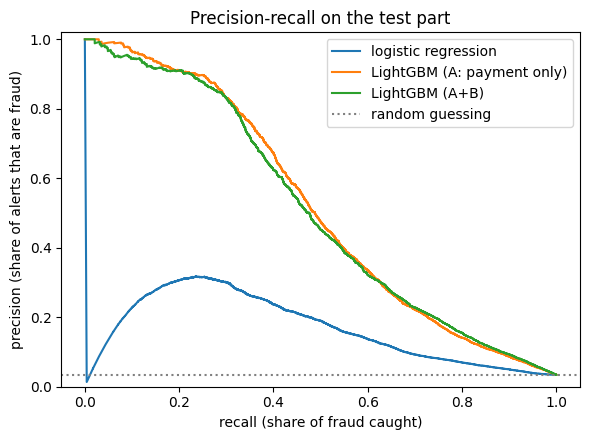

In [10]:
table = pd.DataFrame(results).set_index("model")
print("TEST part (threshold chosen on the validation part)")
print(table.round(4).to_string())

fig, ax = plt.subplots(figsize=(6, 4.5))
for name, (precision, recall) in curves.items():
    ax.plot(recall, precision, label=name)
ax.axhline(labels[is_test].mean(), ls=":", c="grey", label="random guessing")
ax.set_xlabel("recall (share of fraud caught)")
ax.set_ylabel("precision (share of alerts that are fraud)")
ax.set_title("Precision-recall on the test part")
ax.set_ylim(0, 1.02)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "pr_curve.png", dpi=150)
plt.show()

## 9. Does it hold up over time?

The test part is cut into four successive slices of equal duration and the final model is scored on each. Fraud
patterns change; a model that was trained on the past usually does a little worse the further ahead it looks.

In [11]:
test_dt = dt[is_test]
edges = np.linspace(test_dt.min(), test_dt.max() + 1, 5)
drift_rows = []
for i in range(4):
    sl = (test_dt >= edges[i]) & (test_dt < edges[i + 1])
    y_sl, p_sl = labels[is_test][sl], p_test[sl]
    drift_rows.append({"slice": i + 1, "days_after_training": round((edges[i] - t_train) / 86400, 1),
                       "payments": int(sl.sum()), "fraud_rate_%": round(float(y_sl.mean() * 100), 2),
                       "AP": round(float(average_precision_score(y_sl, p_sl)), 4),
                       "ROC_AUC": round(float(roc_auc_score(y_sl, p_sl)), 4)})
drift = pd.DataFrame(drift_rows)
drift.to_csv(OUT_DIR / "drift.csv", index=False)
drift

,slice,days_after_training,payments,fraud_rate_%,AP,ROC_AUC
0,1,39.9,26782,3.35,0.4472,0.8898
1,2,50.4,32800,2.94,0.5051,0.9018
2,3,60.8,30270,3.49,0.5088,0.9041
3,4,71.3,28256,4.06,0.5579,0.9033


## 10. What the model uses

Gain importance: how much each feature improved the model's fit, summed over all the splits that used it. The `V`
columns are anonymised; the others can be read.

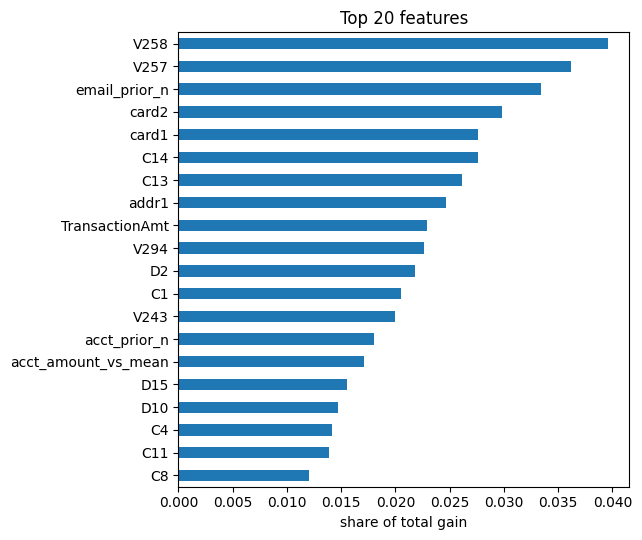

history features (group B) share of gain: 0.0803 | V columns share of gain: 0.3735


,share_of_gain
V258,0.0396
V257,0.0362
email_prior_n,0.0334
card2,0.0298
card1,0.0276
C14,0.0276
C13,0.0261
addr1,0.0247
TransactionAmt,0.0229
V294,0.0226


In [12]:
gain = pd.Series(model.booster_.feature_importance("gain"), index=model.booster_.feature_name()).sort_values(ascending=False)
gain_share = (gain / gain.sum()).round(4)
top = gain_share.head(20)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
top[::-1].plot.barh(ax=ax)
ax.set_xlabel("share of total gain")
ax.set_title("Top 20 features")
fig.tight_layout()
fig.savefig(OUT_DIR / "importance.png", dpi=150)
plt.show()
print("history features (group B) share of gain:", round(float(gain_share[B_FEATURES].sum()), 4),
      "| V columns share of gain:", round(float(gain_share[[c for c in gain_share.index if c.startswith("V")]].sum()), 4))
top.to_frame("share_of_gain")

## 11. Save everything

This writes the model, the feature list, the categories, the thresholds and the metrics, and makes one zip.

In [13]:
def sha256_of(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        while block := fh.read(chunk):
            h.update(block)
    return h.hexdigest()


thresholds = {f"fpr_{fpr:g}": threshold_for_fpr(labels[is_valid], p_val, fpr) for fpr in FPR_TARGETS}
final_row = next(r for r in results if r["model"] == "LightGBM (A+B)")
model.booster_.save_model(str(OUT_DIR / "lgbm_ieee_cis.txt"))
pd.DataFrame(results).to_csv(OUT_DIR / "results.csv", index=False)
gain_share.head(50).to_csv(OUT_DIR / "importance.csv", header=["share_of_gain"])
meta = {
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
    "dataset": "ieee-fraud-detection: train_transaction.csv + train_identity.csv",
    "data_sha256": {name: sha256_of(DATA / name) for name in ("train_transaction.csv", "train_identity.csv")},
    "rows": int(len(df)),
    "fraud_rate": float(labels.mean()),
    "features": ALL_FEATURES,
    "text_features": text_cols,
    "category_levels": {c: [str(v) for v in lv] for c, lv in levels.items()},
    "proxy_account_key": key,
    "best_iteration": int(model.best_iteration_),
    "params": {k: v for k, v in model.get_params().items() if k in
               ("learning_rate", "num_leaves", "min_child_samples", "subsample", "colsample_bytree", "reg_lambda", "random_state")},
    "quick_run": QUICK,
    "split": {"train_end_dt": float(t_train), "valid_end_dt": float(t_valid),
              "payments": split["payments"].to_dict(), "fraud": split["fraud"].to_dict()},
    "thresholds_chosen_on_validation": thresholds,
    "test_metrics": {k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in final_row.items() if k != "model"},
    "drift": drift.to_dict(orient="records"),
    "versions": {"lightgbm": lgb.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
(OUT_DIR / "metadata.json").write_text(json.dumps(meta, indent=2, default=str))
print(json.dumps({k: meta[k] for k in ("best_iteration", "quick_run", "thresholds_chosen_on_validation", "test_metrics")}, indent=2))

archive = shutil.make_archive(str(WORK / "ieee_cis_results"), "zip", OUT_DIR)
print("saved:", archive)
if IN_KAGGLE:
    from IPython.display import FileLink
    os.chdir(WORK)
    print("Download link below, or Save Version > Save & Run All (Commit) to keep the files in the Output tab.")
    display(FileLink(Path(archive).name))

{
  "best_iteration": 762,
  "quick_run": false,
  "thresholds_chosen_on_validation": {
    "fpr_0.05": 0.04966856460261869,
    "fpr_0.01": 0.18624502654184621
  },
  "test_metrics": {
    "AP": 0.5076815995265287,
    "ROC_AUC": 0.9000744929364188,
    "recall@0.05": 0.6338582677165354,
    "precision@0.05": 0.2951758909132577,
    "false_alarm_rate@0.05": 0.05393532320858616,
    "recall@0.01": 0.4406988188976378,
    "precision@0.01": 0.5543175487465181,
    "false_alarm_rate@0.01": 0.01262670548209463
  }
}
saved: /kaggle/working/ieee_cis_results.zip
Download link below, or Save Version > Save & Run All (Commit) to keep the files in the Output tab.


/kaggle/working/ieee_cis_results.zip